# 07_03 — Feature selection per day

The stitched clean acquisition of `07_01`, loaded and cleaned exactly as in `07_02` (same per-shot quantities, group B
one row later within the segment, frozen laser-scope / camera shots dropped). **The camera images are described
without the PCA across images of 07_02**: that PCA is fitted on every stitched shot, so its components see the
shots a model is later tested on (leakage). Instead, two decompositions of each image on its own, no fit:

| method | per shot | from |
|---|---|---|
| **spot-shape PCA** | `BTV_sigma_major`, `BTV_sigma_minor` (RMS sizes along the spot's own axes, mm), `BTV_tilt` (deg), `BTV_ellipticity` (minor / major) | eigen-decomposition of the intensity-weighted 2×2 x–y covariance inside the beam mask of notebook 04 |
| **per-image SVD** | `SVD_s1` … `SVD_s6` | singular values of the binned ROI image (preprocessing of 04_1 / 07_02) |

On a blank image (no beam found) both are NaN, like the classic `BTV_*` parameters.

Then, per segment, from the correlation matrix (`KIND`):

1. **candidates**: variables with |r with `BCM_GUN`| ≥ `R_MIN`
2. **selection**: go through the candidates from the strongest down; keep one only if its |r| with every
   variable already kept is ≤ `R_CROSS`, otherwise mark it as redundant with the first kept variable it clashes with

One figure per day (day = start date of the run), one panel per segment. Blue = kept, grey = redundant.
Saved to `results/data_labelling/segment_correlations/selection_<day>.png`; the union of the kept variables goes to
`selected_features.json`, the input for `FEATURES` in `scripts/extract_features.py`.
Run `07_01` and `05_correlations_runs` (camera parameter cache) first.

In [5]:
import json
import os
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import ndimage

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
STITCHED = REPO / "results" / "data_labelling" / "stitched_index.csv"   # written by 07_01
BTV_CACHE = REPO / "results" / "05_correlations"                        # <run>/btv0125_params.csv from 05_correlations_runs
SEG_DIR = REPO / "results" / "data_labelling" / "segment_correlations"
N_JOBS = min(32, os.cpu_count() or 1)

# loading and cleaning, as 07_02
FLAT_TOP = slice(300, 640)
GROUP_B = ["laser_amp", "lab_laser_power", "PGLA_drop", "PKI15A", "PKI15P", "PKR15A"]
BTV_COLS = ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]
DETREND_K = 51

# selection
KIND = "Overall"   # or "Shot-to-shot (drift removed)"
R_MIN = 0.25       # |r| with BCM_GUN to be a candidate
R_CROSS = 0.5      # max |r| allowed between kept variables
MIN_SHOTS = 500    # segments with fewer kept shots get a warning in the title

KEPT, DROPPED = "#2a78d6", "#c9c8c3"
INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"

idx = pd.read_csv(STITCHED, index_col="shot")
segments = (idx.groupby("segment")
               .agg(run=("run", "first"), first_chunk=("chunk", "min"), last_chunk=("chunk", "max"), shots=("run", "size")))
segments["day"] = segments["run"].str.extract(r"(\d{4}-\d{2}-\d{2})", expand=False)
segments["start"] = segments["run"].str.extract(r"_(\d{2}-\d{2})-\d{2}$", expand=False).str.replace("-", ":")
print(f"{len(idx)} stitched shots, {len(segments)} segments")
segments

83927 stitched shots, 9 segments


,run,first_chunk,last_chunk,shots,day,start
segment,,,,,,
0,acquisition_2026-10-07_21-43-26,11,71,6027,2026-10-07,21:43
1,acquisition_2026-10-08_00-08-19,0,193,19400,2026-10-08,00:08
2,acquisition_2026-10-08_15-42-27,0,1,200,2026-10-08,15:42
3,acquisition_2026-10-08_15-42-27,4,74,7100,2026-10-08,15:42
4,acquisition_2026-10-08_15-42-27,76,120,4500,2026-10-08,15:42
5,acquisition_2026-10-08_21-11-47,0,199,20000,2026-10-08,21:11
6,acquisition_2026-10-09_07-46-07,0,40,4100,2026-10-09,07:46
7,acquisition_2026-10-09_07-46-07,87,106,2000,2026-10-09,07:46
8,acquisition_2026-10-13_21-44-34,15,220,20600,2026-10-13,21:44


## Per-shot table, as 07_02

In [7]:
def chunk_features(fp):
    # Worker, one chunk: scalar features, baseline-subtracted laser pulse, frozen-laser flags, first/last raw pulse.
    with h5py.File(fp, "r") as f:
        sig = f["laser_scope/signal"][()]
        t = f["laser_scope/times"][0]
        pgla = f["PGLA/samples"][:, 0]
        feats = {
            "BCM_GUN": f["BCM_GUN"][()],
            "lab_laser_power": f["lab_laser_power"][()],
            "PGLA_drop": pgla[:, 631] - pgla[:, 636],
            "PKI15A": f["PKI15A/samples"][:, 0, FLAT_TOP].mean(axis=1),
            "PKI15P": f["PKI15P"][:, 0, FLAT_TOP].mean(axis=1),
            "PKR15A": f["PKR15A"][:, 0, FLAT_TOP].mean(axis=1),
            "DHG0130": f["DHG0130"][()],
            "SNH_110": f["SNH_110"][()],
            "SNI_120": f["SNI_120"][()],
        }
    laser = (sig - sig[:, t < 5].mean(axis=1, keepdims=True)).astype(np.float32)
    frozen = np.r_[False, (sig[1:] == sig[:-1]).all(axis=1)]
    return feats, laser, frozen, sig[:1], sig[-1:], t


files = list(dict.fromkeys(idx["file"]))          # chunk files in stitched order
res = Parallel(n_jobs=N_JOBS, verbose=2)(delayed(chunk_features)(fp) for fp in files)

feats = pd.DataFrame({k: np.concatenate([r[0][k] for r in res]) for k in res[0][0]}, index=idx.index)
laser = np.concatenate([r[1] for r in res])
laser_frozen = np.concatenate([r[2] for r in res])
t = res[0][5]
assert len(feats) == len(idx) and np.allclose(feats["BCM_GUN"], idx["BCM_GUN"], equal_nan=True), "stitched index out of date: re-run 07_01"

# frozen check across chunk boundaries (only inside a segment)
starts = np.r_[0, np.cumsum([len(r[2]) for r in res])[:-1]]
seg = idx["segment"].to_numpy()
for i in range(1, len(res)):
    s = starts[i]
    if seg[s] == seg[s - 1]:
        laser_frozen[s] = (res[i][3] == res[i - 1][4]).all()
del res

# laser matched filter, template = mean pulse of the segment
window = (t > 5.6) & (t < 39.8)
laser_amp = np.empty(len(idx))
for k in segments.index:
    m = seg == k
    template = laser[m].mean(axis=0) * window
    laser_amp[m] = laser[m] @ template / (template @ template)
feats.insert(1, "laser_amp", laser_amp)
del laser

# classic camera parameters from the per-run cache of 05_correlations_runs
parts = []
for run in segments["run"].unique():
    p = BTV_CACHE / run / "btv0125_params.csv"
    if not p.exists():
        print(f"no camera cache for {run}: BTV columns are NaN there (run 05_correlations_runs to create it)")
        continue
    b = pd.read_csv(p, index_col="shot")
    b["chunk"] = b["chunk"].str[6:].astype(int)
    b["shot_in_chunk"] = b.groupby("chunk").cumcount()
    b["run"] = run
    parts.append(b)
btv = pd.concat(parts)[["run", "chunk", "shot_in_chunk", "frozen", *BTV_COLS]]
btv = idx[["run", "chunk", "shot_in_chunk"]].merge(btv, on=["run", "chunk", "shot_in_chunk"], how="left")
btv.index = idx.index
print(f"camera parameters found for {btv['amplitude'].notna().sum()} / {len(idx)} shots")

raw = feats.copy()
for c in BTV_COLS:
    raw[f"BTV_{c}"] = btv[c]
btv_frozen = btv["frozen"].eq(True).to_numpy()
print(raw.shape)

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/lustre/work/pdl18409/shared/data/optimisation/measured_data/acquisition_2026-10-07_21-43-26/h5/chunk_00014.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

## Camera: two decompositions of each image on its own

Preprocessing as 04 / 04_1 / 07_02: crop the ROI, subtract the background (median of the top rows), 3×3 median filter.

- **Spot-shape PCA**: beam mask of notebook 04 (Gaussian-smoothed image above 5 % of its peak, largest blob), then
  the intensity-weighted 2×2 covariance of x and y (mm) inside it. Its eigenvalues are the squared RMS sizes along
  the spot's own axes; `sigma_x` / `sigma_y` of the cache are the same sizes along the camera axes only.
- **Per-image SVD**: the image binned 4×4 (200 × 212) as a matrix, rows × columns. `SVD_s1` is the strength of
  the best separable (x-profile × y-profile) approximation, ≈ brightness; the following ones measure what is not
  separable (tilt, structure). The singular vectors are not kept: each image has its own basis, so they cannot be
  compared between shots.

One parallel pass over the stitched chunks; the result is cached in
`segment_correlations/btv0125_shape_svd_stitched.npz` (reused while the stitched shots are unchanged).

In [3]:
ROI = (slice(350, 1150), slice(600, 1450))  # same as notebooks 04 / 04_1
BG_ROWS = slice(0, 150)
THRESHOLD = 0.05                             # beam mask: pixels above 5 % of the peak (04)
BIN = 4
N_SVD = 6
SPOT = ["BTV_sigma_major", "BTV_sigma_minor", "BTV_tilt", "BTV_ellipticity"]
SVDS = [f"SVD_s{k + 1}" for k in range(N_SVD)]
CAMERA_CACHE = SEG_DIR / "btv0125_shape_svd_stitched.npz"


def first_non_empty(obj):
    arrays = [obj[k][:] for k in sorted(obj)] if isinstance(obj, h5py.Group) else obj[:]
    return next((a for a in arrays if a.size), None)


def spot_shape(img, x_mm, y_mm):
    # Spot-shape PCA of one cleaned ROI image -> SPOT; NaN for a blank image (no beam, or the camera sent zeros).
    smooth = ndimage.gaussian_filter(img, 3)
    peak = smooth.max()
    labels, n_blobs = ndimage.label(smooth > THRESHOLD * peak)
    if peak <= 0 or n_blobs == 0:
        return [np.nan] * len(SPOT)
    img = img * (labels == np.bincount(labels.ravel())[1:].argmax() + 1)
    total = img.sum()
    proj_x, proj_y = img.sum(axis=0), img.sum(axis=1)
    dx, dy = x_mm - proj_x @ x_mm / total, y_mm - proj_y @ y_mm / total
    var_x, var_y = proj_x @ dx**2 / total, proj_y @ dy**2 / total
    cov_xy = dy @ img @ dx / total
    minor, major = np.sqrt(np.maximum(np.linalg.eigvalsh([[var_x, cov_xy], [cov_xy, var_y]]), 0))  # ascending
    tilt = 0.5 * np.degrees(np.arctan2(2 * cov_xy, var_x - var_y))
    return [major, minor, tilt, minor / major]


def chunk_camera(fp, x_mm, y_mm):
    # Worker, one chunk: SPOT + SVDS per shot; both NaN on a blank image (its singular values are background only).
    with h5py.File(fp, "r") as f:
        ds = f["BTV0125/image2D"]
        roi = ds[:, ROI[0], ROI[1]]                                   # only ROI and background rows are read
        bg = np.median(ds[:, BG_ROWS, :].reshape(len(roi), -1), axis=1)
    h, w = (s // BIN * BIN for s in roi.shape[1:])
    out = np.full((len(roi), len(SPOT) + N_SVD), np.nan)
    for i, (img, b) in enumerate(zip(roi, bg)):
        img = ndimage.median_filter(img, size=3).astype(np.float32) - b   # median of ints is exact: same as on floats
        out[i, :len(SPOT)] = spot_shape(img, x_mm, y_mm)
        if not np.isnan(out[i, 0]):
            small = img[:h, :w].reshape(h // BIN, BIN, w // BIN, BIN).mean(axis=(1, 3))
            out[i, len(SPOT):] = np.linalg.svd(small, compute_uv=False)[:N_SVD]
    return out


signature = np.array([f"{r}/{c}/{s}" for r, c, s in idx[["run", "chunk", "shot_in_chunk"]].itertuples(index=False)])
cached = np.load(CAMERA_CACHE) if CAMERA_CACHE.exists() else None
if cached is not None and np.array_equal(cached["signature"], signature) and list(cached["columns"]) == SPOT + SVDS:
    print(f"camera: cached {CAMERA_CACHE}")
    camera = cached["values"]
else:
    # pixel -> mm axes, assumed the same for all shots (as notebook 04): first non-empty one over the chunks
    for fp in files:
        with h5py.File(fp, "r") as f:
            x, y = first_non_empty(f["BTV0125/imagePositionSet1"]), first_non_empty(f["BTV0125/imagePositionSet2"])
        if x is not None and y is not None:
            x_mm, y_mm = x[ROI[1]], y[ROI[0]]
            break
    camera = np.concatenate(Parallel(n_jobs=N_JOBS, verbose=2)(delayed(chunk_camera)(fp, x_mm, y_mm) for fp in files))
    np.savez(CAMERA_CACHE, signature=signature, columns=np.array(SPOT + SVDS), values=camera)

for j, c in enumerate(SPOT + SVDS):
    raw[c] = camera[:, j]
raw = raw.dropna(axis=1, how="all")
print(f"blank images (no beam found): {np.isnan(camera[:, 0]).sum()} / {len(camera)}")
raw[SPOT + SVDS].describe().round(3)

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.


[Parallel(n_jobs=32)]: Done  98 tasks      | elapsed:   35.1s


/tmp/ipykernel_2797332/899615861.py:31: RuntimeWarning: invalid value encountered in scalar divide


[Parallel(n_jobs=32)]: Done 301 tasks      | elapsed:  1.5min


[Parallel(n_jobs=32)]: Done 584 tasks      | elapsed:  2.8min


blank images (no beam found): 640 / 83927


[Parallel(n_jobs=32)]: Done 840 out of 840 | elapsed:  4.0min finished


,BTV_sigma_major,BTV_sigma_minor,BTV_tilt,BTV_ellipticity,SVD_s1,SVD_s2,SVD_s3,SVD_s4,SVD_s5,SVD_s6
count,83287.000,83287.000,83287.000,83286.000,83287.000,83287.000,83287.000,83287.000,83287.000,83287.000
mean,0.302,0.250,37.869,0.856,8854.484,1854.084,594.869,406.165,220.569,167.509
std,0.150,0.059,65.483,0.095,3872.984,758.645,296.310,172.475,87.397,71.998
min,0.000,0.000,-90.000,0.000,32.213,0.000,0.000,0.000,0.000,0.000
25%,0.263,0.228,50.024,0.760,6201.557,1411.543,370.050,263.129,138.847,98.383
50%,0.302,0.241,71.128,0.895,7576.801,1768.922,547.239,347.773,208.813,131.091
75%,0.315,0.276,76.636,0.910,11742.544,2376.807,757.742,558.696,290.806,238.073
max,2.636,2.493,90.000,0.995,35081.432,7784.399,3377.817,1474.200,710.609,584.198


## Align (group B one row later, within the segment) and clean, as 07_02

kept 71542 / 83927 shots (dropped 12179 frozen laser, 230 frozen camera, 9 lost to the shift)


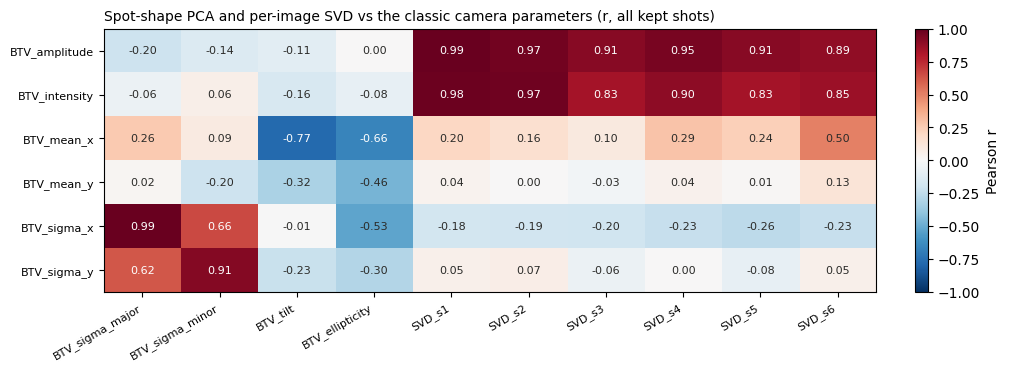

,run,first_chunk,last_chunk,shots,day,start,kept
segment,,,,,,,
0,acquisition_2026-10-07_21-43-26,11,71,6027,2026-10-07,21:43,4637
1,acquisition_2026-10-08_00-08-19,0,193,19400,2026-10-08,00:08,16658
2,acquisition_2026-10-08_15-42-27,0,1,200,2026-10-08,15:42,154
3,acquisition_2026-10-08_15-42-27,4,74,7100,2026-10-08,15:42,5427
4,acquisition_2026-10-08_15-42-27,76,120,4500,2026-10-08,15:42,3855
5,acquisition_2026-10-08_21-11-47,0,199,20000,2026-10-08,21:11,17443
6,acquisition_2026-10-09_07-46-07,0,40,4100,2026-10-09,07:46,3137
7,acquisition_2026-10-09_07-46-07,87,106,2000,2026-10-09,07:46,1780
8,acquisition_2026-10-13_21-44-34,15,220,20600,2026-10-13,21:44,18451


In [4]:
def detrend(df, segment, k=DETREND_K):
    # Remove slow drift: subtract a k-shot centred rolling mean, per segment.
    trend = df.groupby(segment).transform(lambda s: s.rolling(k, center=True, min_periods=1).mean())
    return df - trend


data = raw.copy()
data[GROUP_B] = raw[GROUP_B].groupby(seg).shift(-1)                   # row i now holds group B from row i + 1
laser_frozen_aligned = pd.Series(laser_frozen).groupby(seg).shift(-1).eq(True).to_numpy()
complete = data[GROUP_B].notna().any(axis=1).to_numpy()               # last row of each segment has no partner
keep = ~laser_frozen_aligned & ~btv_frozen & complete
print(f"kept {keep.sum()} / {len(keep)} shots (dropped {laser_frozen_aligned.sum()} frozen laser, "
      f"{btv_frozen.sum()} frozen camera, {(~complete).sum()} lost to the shift)")

data, seg_kept = data[keep], seg[keep]
segments["kept"] = pd.Series(seg_kept).value_counts().reindex(segments.index, fill_value=0)

# what the new camera features are, in terms of the classic parameters (all kept shots)
classic = [f"BTV_{c}" for c in BTV_COLS]
naming = pd.DataFrame({c: data[classic].corrwith(data[c]) for c in SPOT + SVDS})
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
im = ax.imshow(naming, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(naming.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(r) > 0.6 else INK)
ax.set_xticks(range(naming.shape[1]), naming.columns, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(classic)), classic, fontsize=8)
ax.set_title("Spot-shape PCA and per-image SVD vs the classic camera parameters (r, all kept shots)", fontsize=10, loc="left")
fig.colorbar(im, ax=ax, label="Pearson r")
fig.savefig(SEG_DIR / "shape_svd_vs_classic.png", dpi=130, bbox_inches="tight")
plt.show()
segments

## Selection per segment

Correlation matrix of every segment (`KIND`; segments with fewer than 2 × `DETREND_K` kept shots are skipped, as
07_02), then the greedy selection.

In [5]:
def select(m):
    # Greedy selection: candidates by |r with BCM_GUN|, keep if not redundant with an already kept one.
    vs_bcm = m["BCM_GUN"].drop("BCM_GUN")
    candidates = vs_bcm[vs_bcm.abs() >= R_MIN].sort_values(key=abs, ascending=False)
    rows, kept = [], []
    for name, r in candidates.items():
        clash = next((k for k in kept if abs(m.loc[name, k]) > R_CROSS), None)
        rows.append({"variable": name, "r_bcm": r, "kept": clash is None,
                     "redundant_with": clash, "r_clash": m.loc[name, clash] if clash else np.nan})
        if clash is None:
            kept.append(name)
    return pd.DataFrame(rows, columns=["variable", "r_bcm", "kept", "redundant_with", "r_clash"])


selection = {}
for k in segments.index:
    d = data[seg_kept == k]
    if len(d) < 2 * DETREND_K:
        print(f"segment {k}: only {len(d)} shots, skipped")
        continue
    m = d.corr() if KIND == "Overall" else detrend(d, seg_kept[seg_kept == k]).corr()
    selection[k] = select(m)
summary = pd.concat(selection, names=["segment"]).reset_index(level=0)
summary.round(2)

,segment,variable,r_bcm,kept,redundant_with,r_clash
0,0,SVD_s1,0.83,True,None,NaN
1,0,BTV_amplitude,0.55,False,SVD_s1,0.68
2,0,lab_laser_power,0.54,False,SVD_s1,0.61
3,0,BTV_intensity,0.49,False,SVD_s1,0.57
4,0,SVD_s5,0.38,True,None,NaN
...,...,...,...,...,...,...
2,8,PKI15A,-0.37,True,None,NaN
3,8,SVD_s3,-0.36,True,None,NaN
4,8,SVD_s5,-0.33,False,SVD_s3,0.80
5,8,BTV_intensity,-0.33,False,SVD_s3,0.73


## One figure per day

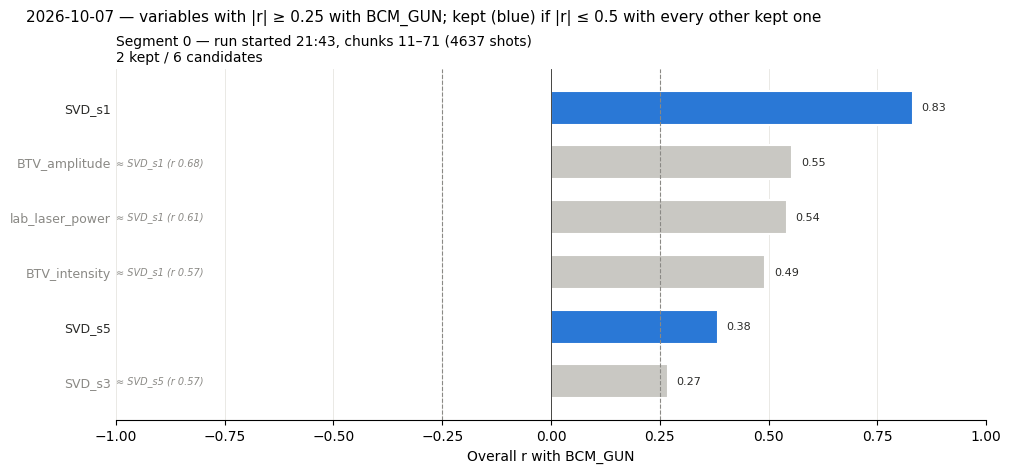

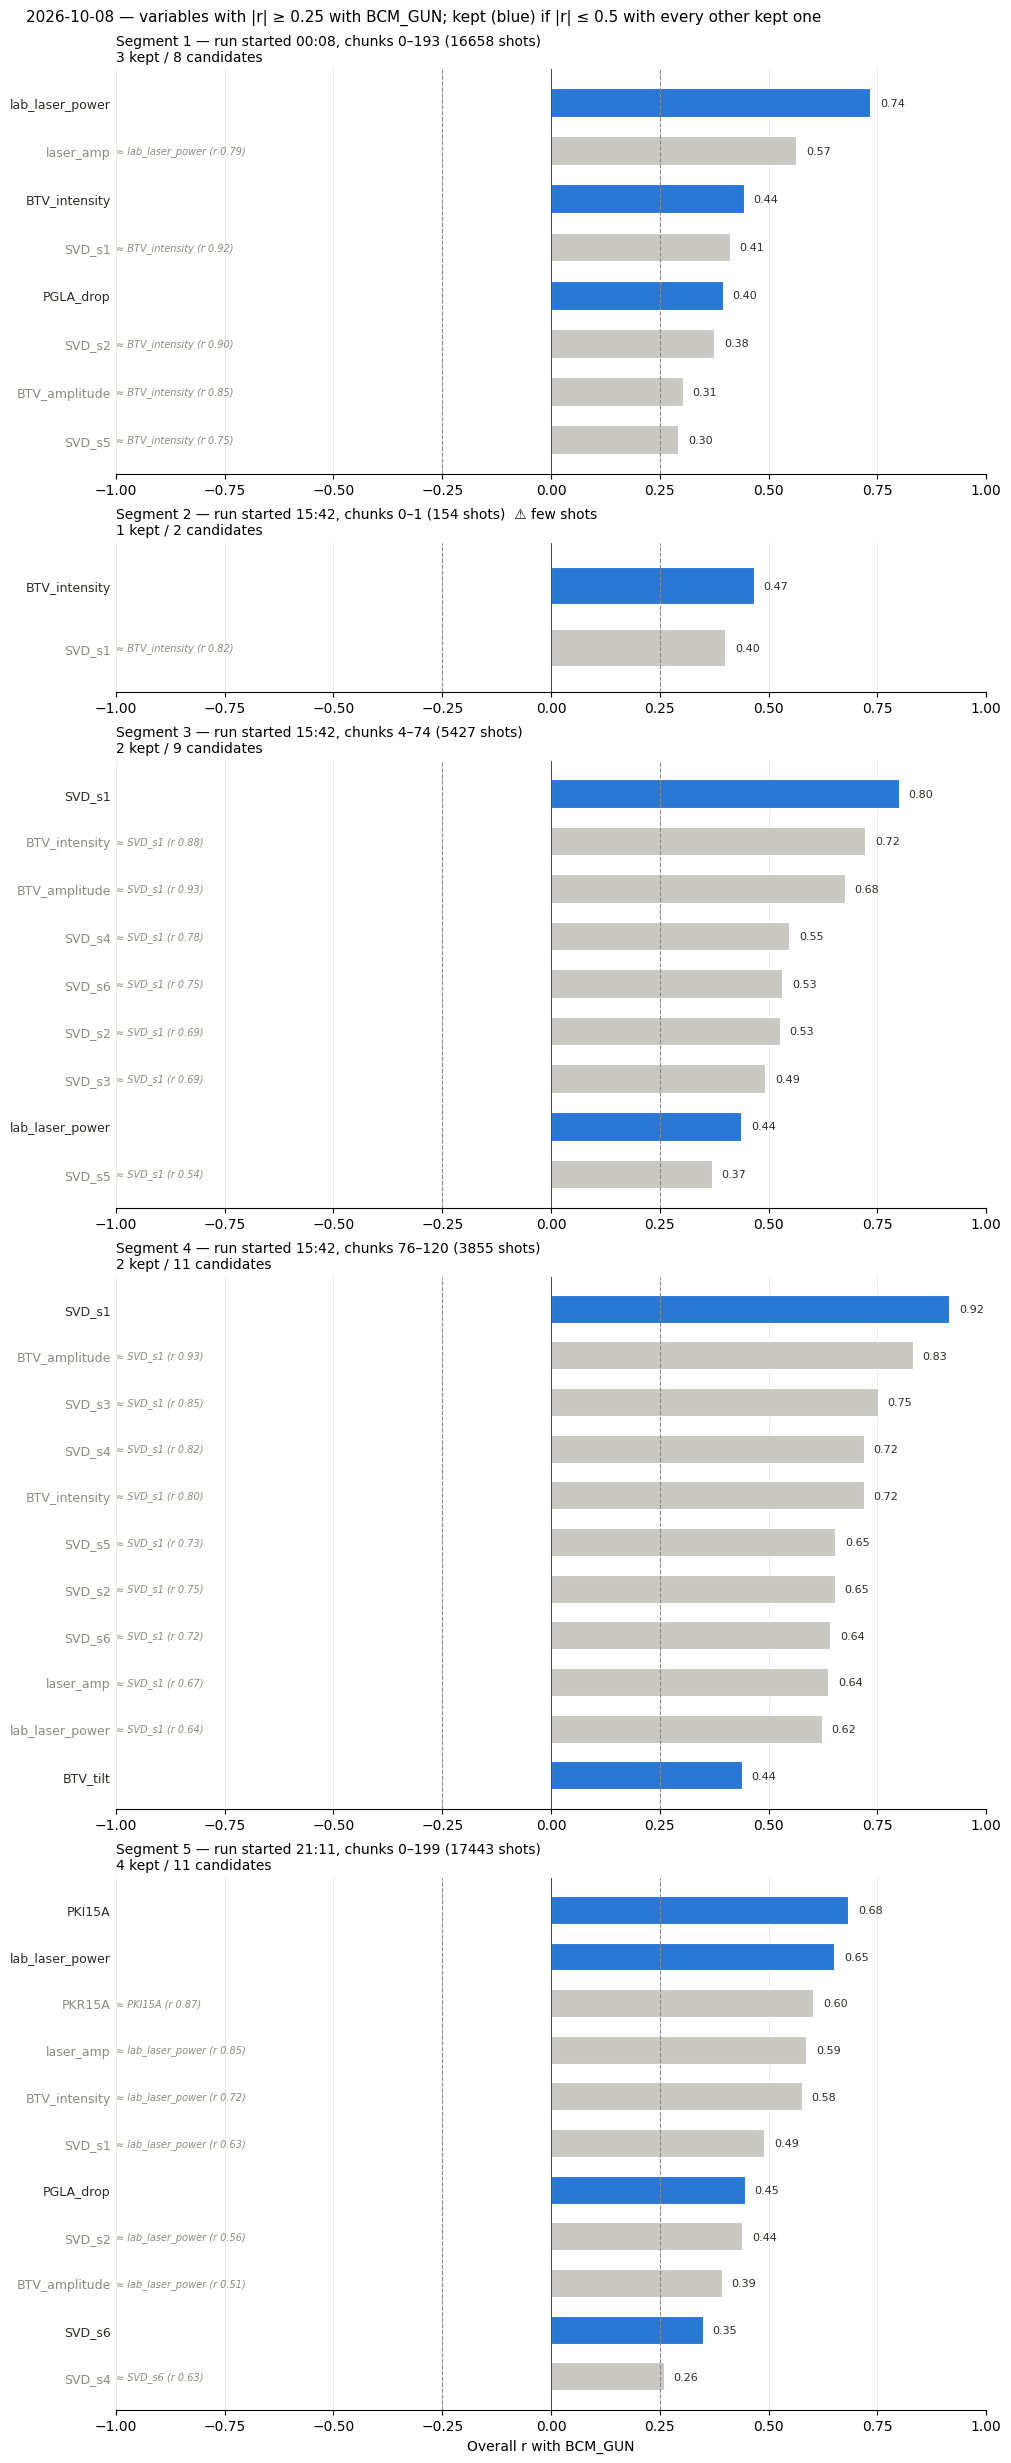

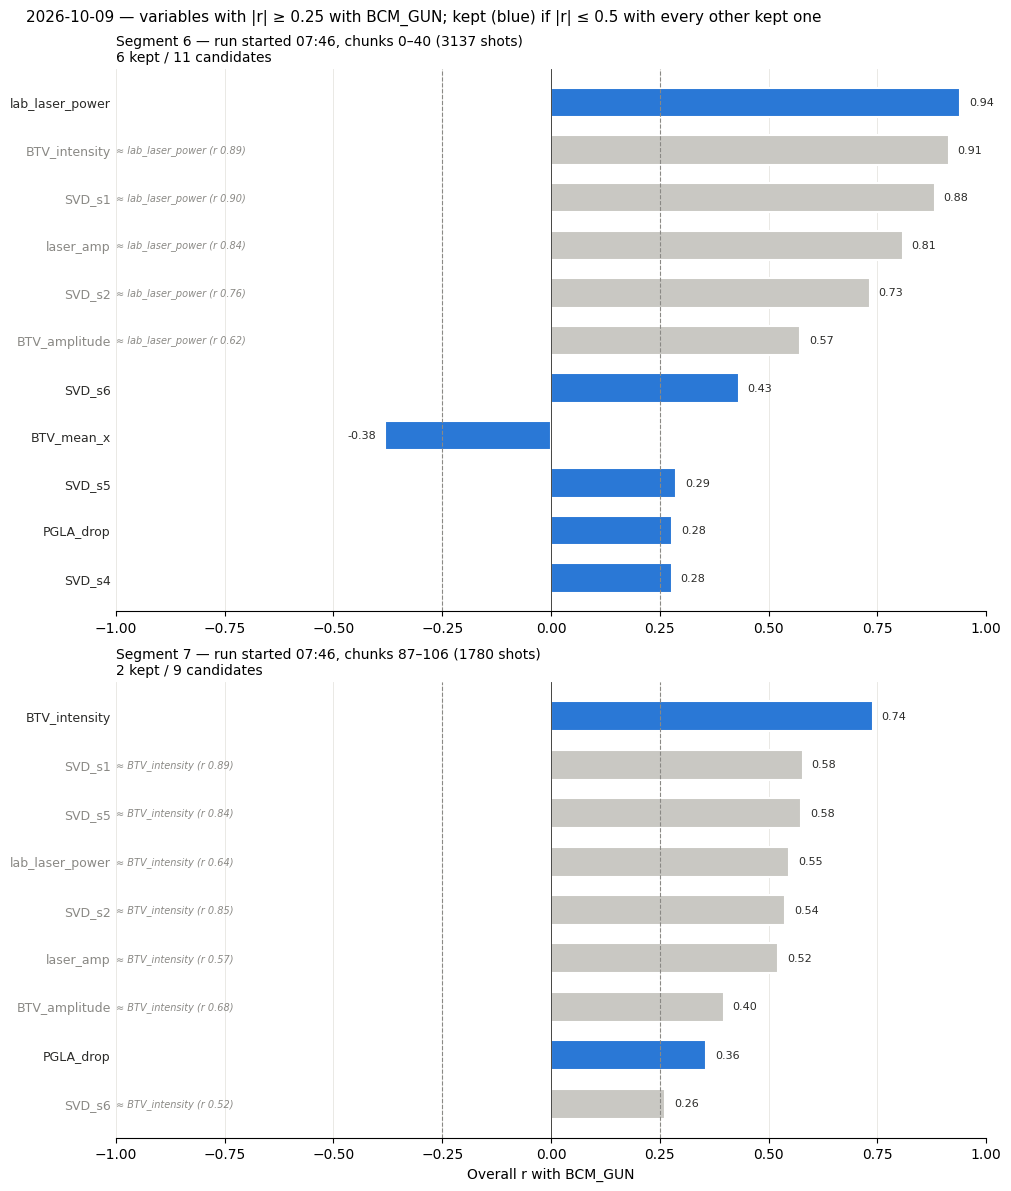

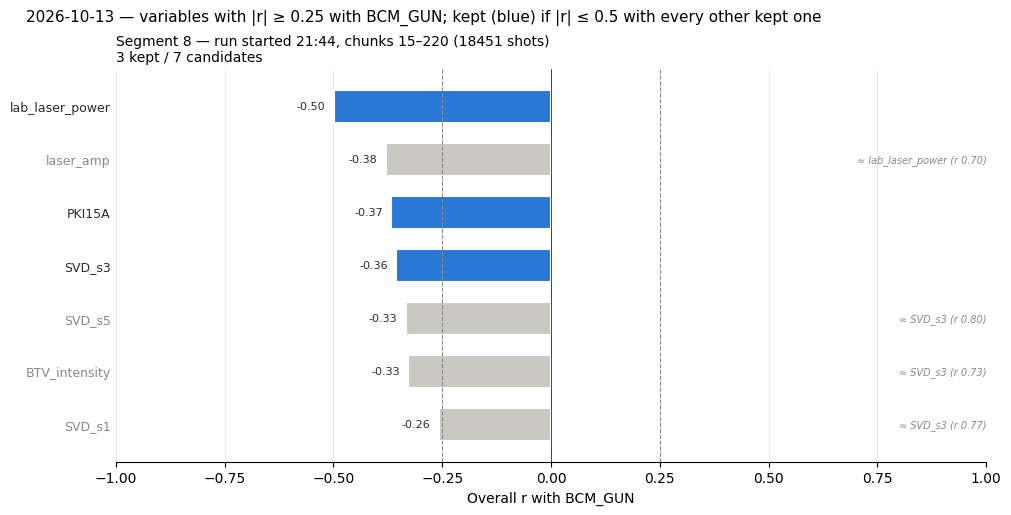

In [6]:
def panel(ax, sel, title):
    sel = sel.iloc[::-1]                       # strongest at the top
    y = np.arange(len(sel))
    colors = [KEPT if k else DROPPED for k in sel["kept"]]
    ax.barh(y, sel["r_bcm"], height=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for yi, (_, row) in zip(y, sel.iterrows()):
        inside = row["r_bcm"] > 0
        ax.text(row["r_bcm"] + (0.02 if inside else -0.02), yi, f"{row['r_bcm']:.2f}",
                va="center", ha="left" if inside else "right", fontsize=8, color=INK)
        if not row["kept"]:
            note = f"≈ {row['redundant_with']} (r {row['r_clash']:.2f})"
            ax.text(-1.0 if inside else 1.0, yi, note, va="center", ha="left" if inside else "right",
                    fontsize=7, color=MUTED, style="italic")
    ax.set_yticks(y, sel["variable"], fontsize=9)
    for yt, k in zip(ax.get_yticklabels(), sel["kept"]):
        yt.set_color(INK if k else MUTED)
    for x in (-R_MIN, R_MIN):
        ax.axvline(x, color=MUTED, lw=0.8, ls="--")
    ax.axvline(0, color=INK, lw=0.6)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.7, max(len(sel), 1) - 0.3)
    ax.grid(axis="x", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(title, fontsize=10, loc="left")
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0)


for day, segs in segments.loc[list(selection)].groupby("day"):
    n = len(segs)
    heights = [max(len(selection[k]), 1) for k in segs.index]
    fig, axes = plt.subplots(n, 1, figsize=(10, 0.42 * sum(heights) + 1.3 * n + 0.8),
                             gridspec_kw={"height_ratios": [h + 1.5 for h in heights]}, squeeze=False,
                             layout="constrained")
    for ax, (k, info) in zip(axes[:, 0], segs.iterrows()):
        sel = selection[k]
        n_kept = int(sel["kept"].sum())
        warn = "  ⚠ few shots" if info["kept"] < MIN_SHOTS else ""
        title = (f"Segment {k} — run started {info['start']}, chunks {info['first_chunk']}–{info['last_chunk']} "
                 f"({info['kept']} shots){warn}\n{n_kept} kept / {len(sel)} candidates")
        panel(ax, sel, title)
    axes[-1, 0].set_xlabel(f"{KIND} r with BCM_GUN")
    fig.suptitle(f"{day} — variables with |r| ≥ {R_MIN} with BCM_GUN; kept (blue) if |r| ≤ {R_CROSS} with every other kept one",
                 fontsize=11, x=0.02, ha="left")
    fig.savefig(SEG_DIR / f"selection_{day}.png", dpi=130, bbox_inches="tight")
    plt.show()

## Feature set for the model

Union of all variables kept in **at least one** segment, even if they are redundant or below `R_MIN` in others.
`kept_in` / `candidate_in`: in how many segments the variable was kept / was a candidate.
Saved to `segment_correlations/selected_features.json` together with the selection parameters.

In [7]:
kept = summary[summary["kept"]]
features = (summary.groupby("variable")
            .agg(kept_in=("kept", "sum"), candidate_in=("kept", "size"),
                 max_abs_r=("r_bcm", lambda r: r.abs().max()))
            .assign(segments_kept=kept.groupby("variable")["segment"].agg(list))
            .query("kept_in > 0")
            .sort_values(["kept_in", "max_abs_r"], ascending=False))
FEATURES = features.index.tolist()

print(f"{len(FEATURES)} features kept in at least one of {len(selection)} segments:")
print(FEATURES)
display(features.round(2))

with open(SEG_DIR / "selected_features.json", "w") as f:
    json.dump({"features": FEATURES, "kind": KIND, "R_MIN": R_MIN, "R_CROSS": R_CROSS,
               "segments": [int(k) for k in selection]}, f, indent=2)
print(f"saved -> {SEG_DIR / 'selected_features.json'}")

11 features kept in at least one of 9 segments:
['lab_laser_power', 'PGLA_drop', 'SVD_s1', 'BTV_intensity', 'PKI15A', 'SVD_s5', 'SVD_s6', 'SVD_s3', 'SVD_s4', 'BTV_tilt', 'BTV_mean_x']


,kept_in,candidate_in,max_abs_r,segments_kept
variable,,,,
lab_laser_power,5,8,0.94,"[1, 3, 5, 6, 8]"
PGLA_drop,4,4,0.45,"[1, 5, 6, 7]"
SVD_s1,3,9,0.92,"[0, 3, 4]"
BTV_intensity,3,9,0.91,"[1, 2, 7]"
PKI15A,2,2,0.68,"[5, 8]"
SVD_s5,2,7,0.65,"[0, 6]"
SVD_s6,2,5,0.64,"[5, 6]"
SVD_s3,1,4,0.75,[8]
SVD_s4,1,4,0.72,[6]


saved -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/data_labelling/segment_correlations/selected_features.json


## Same feature set with the new run?

**New segments** are those of runs not yet in the per-segment datasets (`results/datasets/manifest.json`), i.e. not
yet extracted by `scripts/extract_features.py`; the others are the **old** segments. Compared:
- **in extract_features.py:** its `FEATURES`, what the datasets hold now (from the old segments' selection);
- **old union / new union:** the variables kept in at least one old segment / in at least one segment, new included
  (the feature set above);
- **per new segment:** what the selection did with each variable there: kept, redundant with a kept one (≈), or
  below `R_MIN`.

If the new union equals `FEATURES`, the new segments only need `extract_features.py` to be run again.

In [8]:
import sys
sys.path.insert(0, str(REPO / "scripts"))
import extract_features                                                # only its configuration is used

extracted = {s["run"] for s in json.loads((REPO / "results" / "datasets" / "manifest.json").read_text())["segments"]}
NEW = [k for k in selection if segments.loc[k, "run"] not in extracted]
OLD = [k for k in selection if k not in NEW]
print(f"old segments {OLD}, new segments {NEW}")


def kept_in(segs):
    return set(summary.loc[summary["segment"].isin(segs) & summary["kept"], "variable"])


def fate(k, v):
    # what the selection of segment k did with variable v
    row = selection[k].set_index("variable").reindex([v]).iloc[0]
    if pd.isna(row["r_bcm"]):
        return f"|r| < {R_MIN}"
    return f"kept, r {row['r_bcm']:.2f}" if row["kept"] else f"≈ {row['redundant_with']}, r {row['r_bcm']:.2f}"


current, old_union, new_union = set(extract_features.FEATURES), kept_in(OLD), kept_in(OLD + NEW)
variables = sorted(current | new_union, key=lambda v: (-(summary["kept"] & (summary["variable"] == v)).sum(), v))
compare = pd.DataFrame({
    "in extract_features.py": [v in current for v in variables],
    "old union": [v in old_union for v in variables],
    f"kept in old segments (of {len(OLD)})": [int((summary["kept"] & (summary["variable"] == v)
                                                   & summary["segment"].isin(OLD)).sum()) for v in variables],
    **{f"new seg {k}": [fate(k, v) for v in variables] for k in NEW},
    "new union": [v in new_union for v in variables],
}, index=pd.Index(variables, name="variable"))
display(compare)

added, dropped = sorted(new_union - current), sorted(current - new_union)
print(f"old union == FEATURES of extract_features.py: {old_union == current}")
print(f"kept on the new segment(s): {sorted(kept_in(NEW))}")
if not added and not dropped:
    print("-> same feature set: extract_features.py only has to be run again for the new segment(s)")
else:
    print(f"-> different feature set: would add {added}, drop {dropped}")

old segments [0, 1, 2, 3, 4, 5, 6, 7], new segments [8]


,in extract_features.py,old union,kept in old segments (of 8),new seg 8,new union
variable,,,,,
lab_laser_power,True,True,4,"kept, r -0.50",True
PGLA_drop,True,True,4,|r| < 0.25,True
BTV_intensity,True,True,3,"≈ SVD_s3, r -0.33",True
SVD_s1,True,True,3,"≈ SVD_s3, r -0.26",True
PKI15A,True,True,1,"kept, r -0.37",True
SVD_s5,True,True,2,"≈ SVD_s3, r -0.33",True
SVD_s6,True,True,2,|r| < 0.25,True
BTV_mean_x,True,True,1,|r| < 0.25,True
BTV_tilt,True,True,1,|r| < 0.25,True


old union == FEATURES of extract_features.py: True
kept on the new segment(s): ['PKI15A', 'SVD_s3', 'lab_laser_power']
-> different feature set: would add ['SVD_s3'], drop []


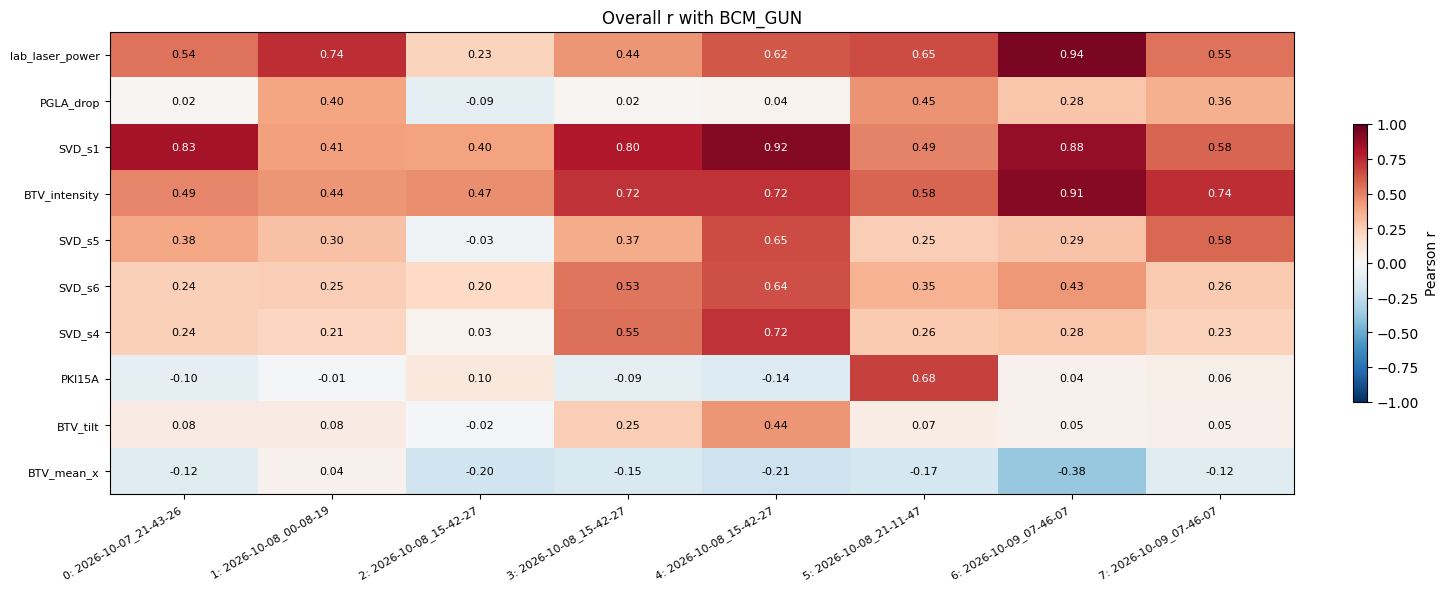

,0: 2026-10-07_21-43-26,1: 2026-10-08_00-08-19,2: 2026-10-08_15-42-27,3: 2026-10-08_15-42-27,4: 2026-10-08_15-42-27,5: 2026-10-08_21-11-47,6: 2026-10-09_07-46-07,7: 2026-10-09_07-46-07
lab_laser_power,0.54,0.74,0.23,0.44,0.62,0.65,0.94,0.55
PGLA_drop,0.02,0.40,-0.09,0.02,0.04,0.45,0.28,0.36
SVD_s1,0.83,0.41,0.40,0.80,0.92,0.49,0.88,0.58
BTV_intensity,0.49,0.44,0.47,0.72,0.72,0.58,0.91,0.74
SVD_s5,0.38,0.30,-0.03,0.37,0.65,0.25,0.29,0.58
SVD_s6,0.24,0.25,0.20,0.53,0.64,0.35,0.43,0.26
SVD_s4,0.24,0.21,0.03,0.55,0.72,0.26,0.28,0.23
PKI15A,-0.10,-0.01,0.10,-0.09,-0.14,0.68,0.04,0.06
BTV_tilt,0.08,0.08,-0.02,0.25,0.44,0.07,0.05,0.05
BTV_mean_x,-0.12,0.04,-0.20,-0.15,-0.21,-0.17,-0.38,-0.12


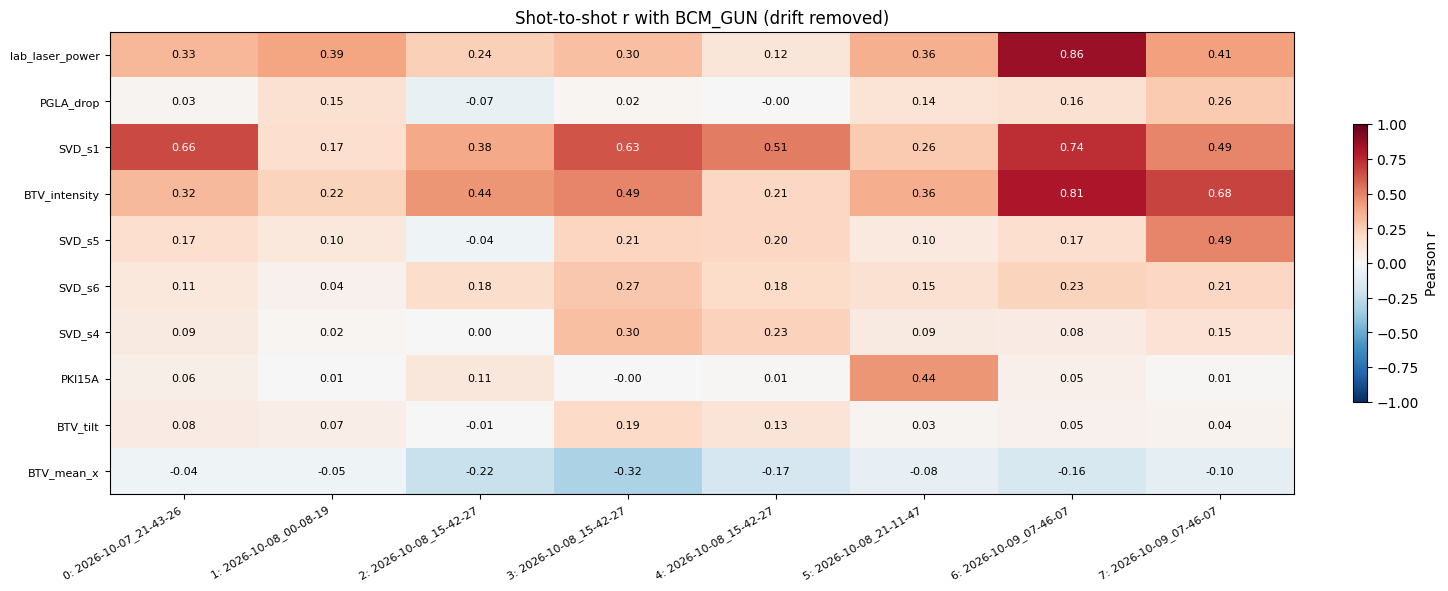

,0: 2026-10-07_21-43-26,1: 2026-10-08_00-08-19,2: 2026-10-08_15-42-27,3: 2026-10-08_15-42-27,4: 2026-10-08_15-42-27,5: 2026-10-08_21-11-47,6: 2026-10-09_07-46-07,7: 2026-10-09_07-46-07
lab_laser_power,0.33,0.39,0.24,0.30,0.12,0.36,0.86,0.41
PGLA_drop,0.03,0.15,-0.07,0.02,-0.00,0.14,0.16,0.26
SVD_s1,0.66,0.17,0.38,0.63,0.51,0.26,0.74,0.49
BTV_intensity,0.32,0.22,0.44,0.49,0.21,0.36,0.81,0.68
SVD_s5,0.17,0.10,-0.04,0.21,0.20,0.10,0.17,0.49
SVD_s6,0.11,0.04,0.18,0.27,0.18,0.15,0.23,0.21
SVD_s4,0.09,0.02,0.00,0.30,0.23,0.09,0.08,0.15
PKI15A,0.06,0.01,0.11,-0.00,0.01,0.44,0.05,0.01
BTV_tilt,0.08,0.07,-0.01,0.19,0.13,0.03,0.05,0.04
BTV_mean_x,-0.04,-0.05,-0.22,-0.32,-0.17,-0.08,-0.16,-0.10


In [9]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = Path("../results/datasets")   # written by scripts/extract_features.py
DETREND_K = 51                           # shot-to-shot: subtract a 51-shot centred rolling mean, as in 05 / 07_02

manifest = json.loads((DATASETS / "manifest.json").read_text())
overall, shot2shot = {}, {}
for info in manifest["segments"]:
    d = np.load(DATASETS / info["file"])
    df = pd.DataFrame(d["X"], columns=d["features"]).assign(BCM_GUN=d["y"])[d["valid"]]  # valid rows only
    name = f"{info['segment']}: {info['run'].removeprefix('acquisition_')}"
    overall[name] = df.corr()["BCM_GUN"].drop("BCM_GUN")
    detr = df - df.rolling(DETREND_K, center=True, min_periods=1).mean()
    shot2shot[name] = detr.corr()["BCM_GUN"].drop("BCM_GUN")

for title, table in [("Overall r with BCM_GUN", pd.DataFrame(overall)),
                     ("Shot-to-shot r with BCM_GUN (drift removed)", pd.DataFrame(shot2shot))]:
    fig, ax = plt.subplots(figsize=(1.3 * table.shape[1] + 4, 0.38 * len(table) + 2), constrained_layout=True)
    im = ax.imshow(table, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for (i, j), r in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(r) > 0.6 else "black")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(table)), table.index, fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.6, label="Pearson r")
    plt.show()
    display(table.round(2))